# Statystyki konkretnego treningu

In [ ]:
import sys
from pathlib import Path
PROJECT_ROOT = Path.cwd().parent
sys.path.insert(0, str(PROJECT_ROOT))
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from model.training_orchiestration import ModelRun


MODEL_CATALOG = PROJECT_ROOT / "model" / "model_catalog"
DATA_PATH = PROJECT_ROOT / "data"

RUN_NAME = "20261120_182042_TrainingMode.DEBUG_279407" #do wpisania nazwa katalogu gdzie jest model


RUN_DIR = MODEL_CATALOG / RUN_NAME
run = ModelRun(RUN_DIR)

print("Selected run:", RUN_DIR)
print("Config:", run.config.to_dict())

Selected run: c:\Users\Bcom_\Documents\Projekty\SpeakerAnimator\SpeakerAnimatorPython\model\model_catalog\20261120_182042_TrainingMode.DEBUG_279407
Config: {'data_path': '../data', 'train_split_name': 'train_clean_100', 'test_split_name': 'test_clean', 'debug_size': 200, 'seed': 0, 'val_ratio': 0.1, 'sample_rate': 16000, 'n_fft': 400, 'hop_length': 160, 'n_mels': 80, 'ignore_index': -100, 'hidden_dim': 256, 'dropout': 0.2, 'num_epochs': 10, 'batch_size': 8, 'lr': 0.0003, 'num_workers': 4, 'prefetch_factor': 2, 'use_amp': True, 'mode': 'debug', 'model_catalog_dir': './model_catalog'}


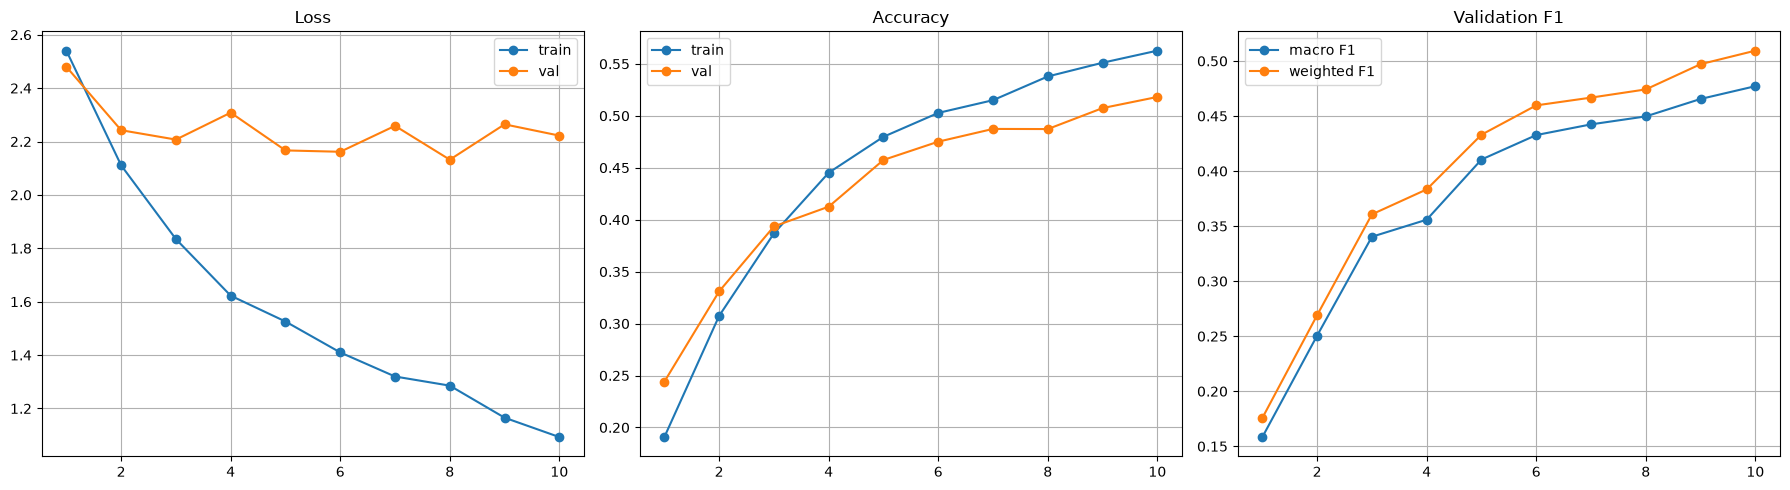

In [2]:
history_path = RUN_DIR / "training_history.json"

with open(history_path, "r", encoding="utf-8") as f:
    history = json.load(f)

df = pd.DataFrame(history)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

axes[0].plot(df["epoch"], df["train_loss"], marker="o", label="train")
axes[0].plot(df["epoch"], df["val_loss"], marker="o", label="val")
axes[0].set_title("Loss")
axes[0].legend()
axes[0].grid(True)

axes[1].plot(df["epoch"], df["train_acc"], marker="o", label="train")
axes[1].plot(df["epoch"], df["val_acc"], marker="o", label="val")
axes[1].set_title("Accuracy")
axes[1].legend()
axes[1].grid(True)

if "val_f1_macro" in df.columns:
    axes[2].plot(df["epoch"], df["val_f1_macro"], marker="o", label="macro F1")
    axes[2].plot(df["epoch"], df["val_f1_weighted"], marker="o", label="weighted F1")
    axes[2].set_title("Validation F1")
    axes[2].legend()
    axes[2].grid(True)

plt.tight_layout()
plt.show()

In [3]:
from datasets import load_from_disk

dataset = load_from_disk(DATA_PATH)
test_split = dataset["test_clean"]

test_results = run.test(test_split, batch_size=4, num_workers=0)

c:\Users\Bcom_\Documents\Projekty\SpeakerAnimator\SpeakerAnimatorPython\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Testing using device: cuda


Precomputing test features: 100%|██████████| 2620/2620 [01:10<00:00, 37.34it/s]


Test loss: 1.4508
Test accuracy: 0.5104
Test results saved to: c:\Users\Bcom_\Documents\Projekty\SpeakerAnimator\SpeakerAnimatorPython\model\model_catalog\20261120_182042_TrainingMode.DEBUG_279407\test_results.json
              precision    recall  f1-score   support

          CH       0.42      0.89      0.57     41551
          DD       0.65      0.20      0.31    157366
           E       0.45      0.70      0.55    139862
          FF       0.54      0.57      0.55     64359
          PP       0.42      0.40      0.41    100925
          RR       0.64      0.73      0.68    118041
          SS       0.77      0.87      0.82    155571
          TH       0.30      0.50      0.38     45343
          aa       0.69      0.26      0.38    221189
          ih       0.59      0.53      0.56    165121
          kk       0.42      0.58      0.49     96019
          nn       0.55      0.37      0.44    179086
          oh       0.37      0.69      0.49     65995
          ou       0.45     

In [4]:
report = test_results["report_dict"]

non_class_keys = {
    "accuracy",
    "macro avg",
    "weighted avg",
    "micro avg",
    "samples",
}

rows = []

for key, value in report.items():
    if key in non_class_keys:
        continue

    if isinstance(value, dict):
        rows.append(
            {
                "class": key,
                "precision": value.get("precision"),
                "recall": value.get("recall"),
                "f1-score": value.get("f1-score"),
                "support": value.get("support"),
            }
        )

per_class = pd.DataFrame(rows)
per_class = per_class.sort_values("support", ascending=False)

per_class

,class,precision,recall,f1-score,support
8,aa,0.685135,0.259131,0.376038,221189.0
11,nn,0.552423,0.366762,0.440842,179086.0
9,ih,0.590193,0.527825,0.557270,165121.0
1,DD,0.649059,0.203170,0.309469,157366.0
6,SS,0.768956,0.869468,0.816129,155571.0
2,E,0.453102,0.698803,0.549749,139862.0
5,RR,0.641801,0.730975,0.683492,118041.0
4,PP,0.419510,0.399990,0.409517,100925.0
10,kk,0.424731,0.577219,0.489371,96019.0
12,oh,0.374829,0.691068,0.486037,65995.0


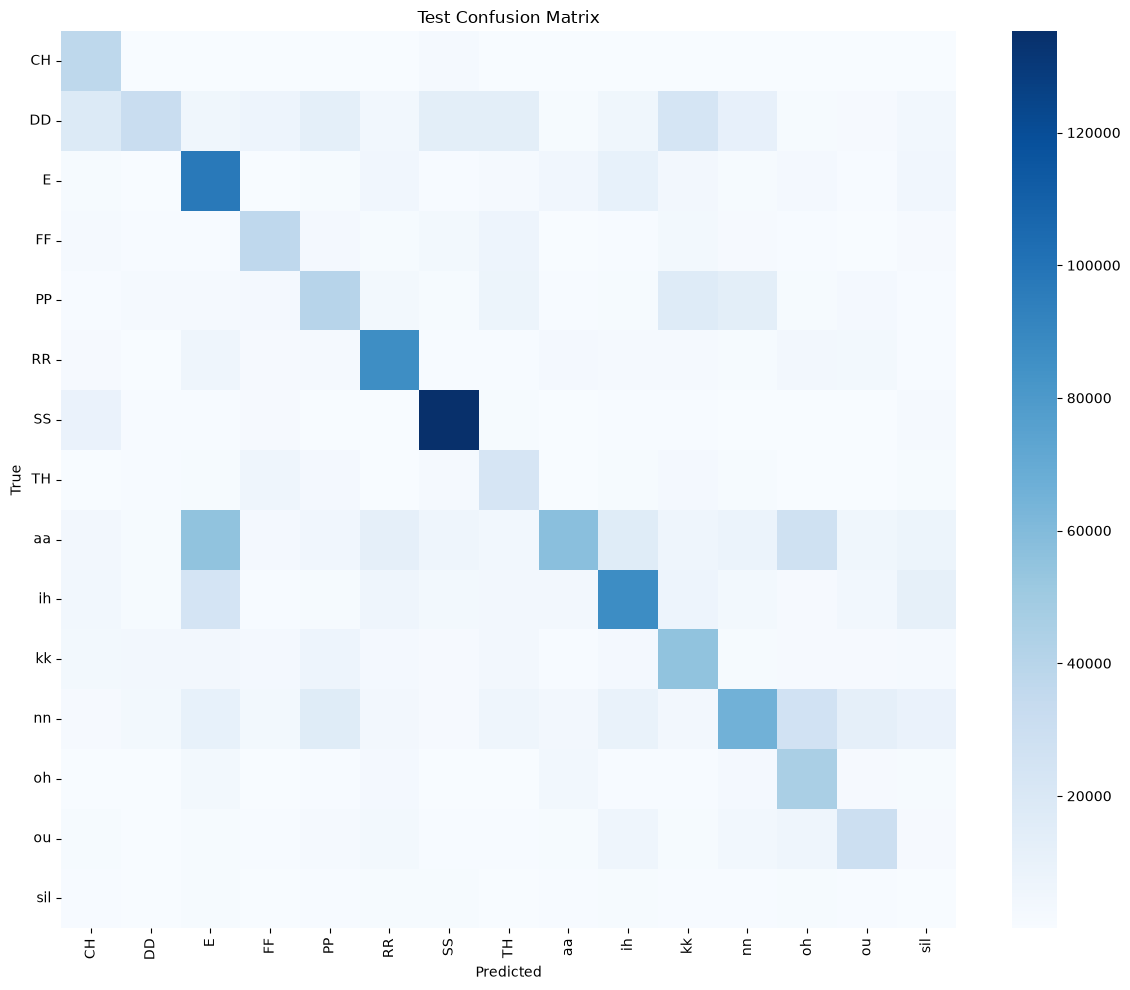

In [ ]:
cm = np.array(test_results["confusion_matrix"])
labels = test_results["labels"]

plt.figure(figsize=(12, 10))

sns.heatmap(
    cm,
    annot=False,
    fmt="d",
    cmap="Blues",
    xticklabels=labels,
    yticklabels=labels,
)

plt.title("Test Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("True")
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

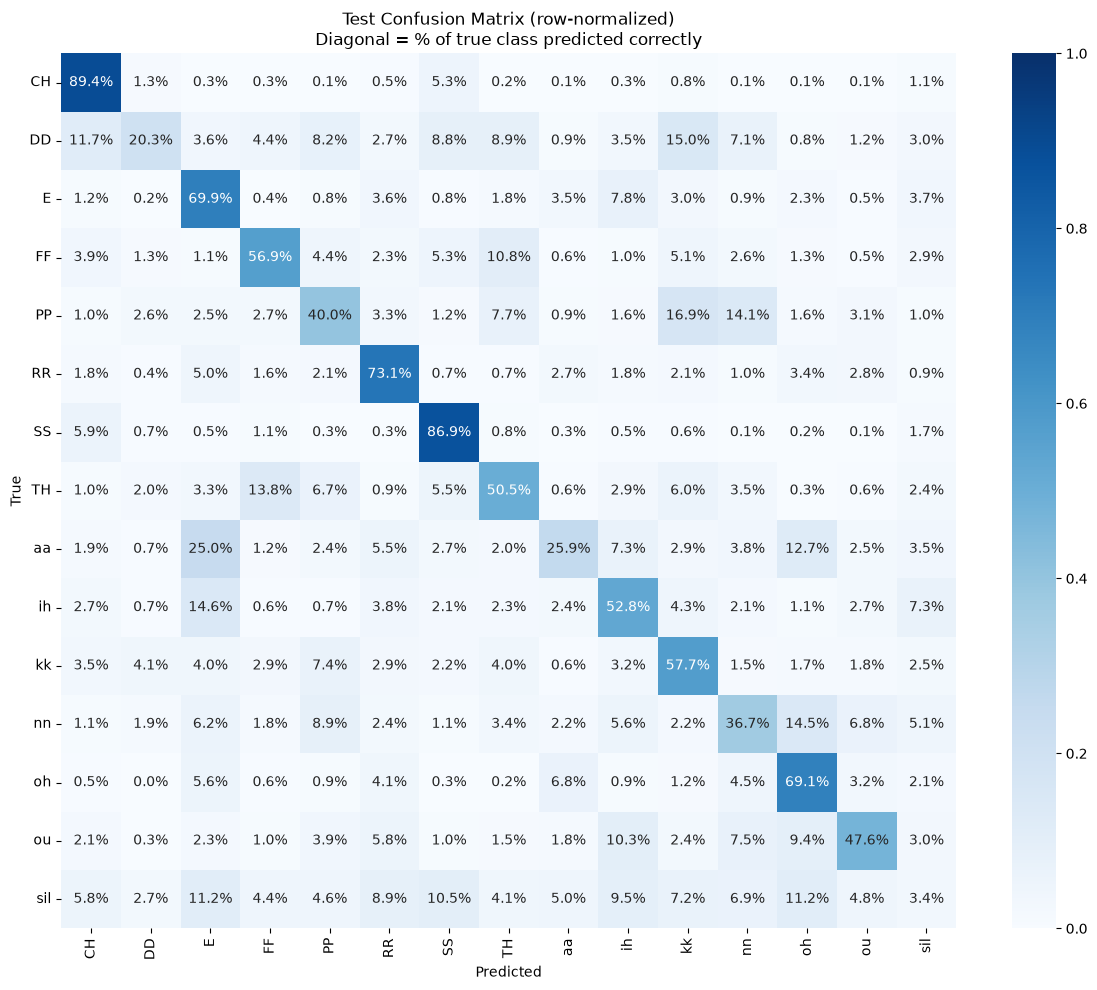

In [ ]:
cm = np.array(test_results["confusion_matrix"], dtype=np.float64)
labels = test_results["labels"]

row_sums = cm.sum(axis=1, keepdims=True)

cm_norm = np.divide(
    cm,
    row_sums,
    out=np.zeros_like(cm),
    where=row_sums != 0,
)

plt.figure(figsize=(12, 10))

sns.heatmap(
    cm_norm,
    annot=True,
    fmt=".1%",
    cmap="Blues",
    xticklabels=labels,
    yticklabels=labels,
    vmin=0,
    vmax=1,
)

plt.title("Test Confusion Matrix (%)")
plt.xlabel("Predicted")
plt.ylabel("True")
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

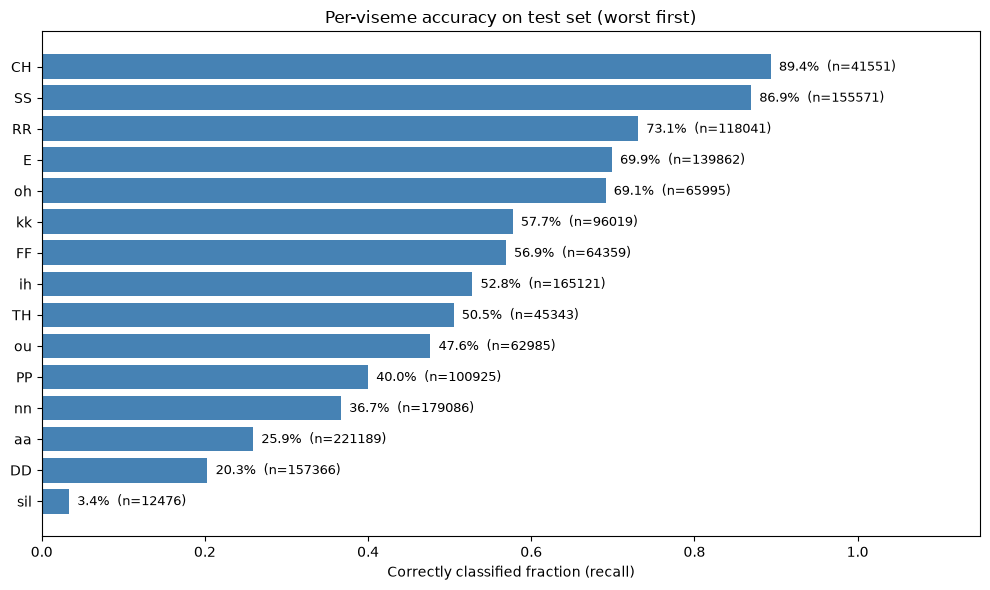

In [ ]:
cm_counts = np.array(test_results["confusion_matrix"], dtype=np.int64)
recall_per_class = np.diag(cm_norm)
support = cm_counts.sum(axis=1)

order = np.argsort(recall_per_class)

plt.figure(figsize=(10, 6))
plt.barh(
    [labels[i] for i in order],
    recall_per_class[order],
    color="steelblue",
)

for idx, i in enumerate(order):
    plt.text(
        recall_per_class[i] + 0.01,
        idx,
        f"{recall_per_class[i]:.1%}  (n={support[i]})",
        va="center",
        fontsize=9,
    )

plt.xlim(0, 1.15)
plt.xlabel("Correctly classified fraction (recall)")
plt.title("Per-viseme accuracy on test set")
plt.tight_layout()
plt.show()

In [6]:
import IPython.display as ipd

sample_idx = 0
sample = test_split[sample_idx]

audio_array = sample["audio"]["array"]
sample_rate = sample["audio"]["sampling_rate"]

probs, labels = run.predict_audio(
    audio_array,
    sample_rate=sample_rate,
)

print("Probability shape:", probs.shape)
print("Labels:", labels)

print("Transcript:", sample.get("transcript"))

ipd.display(
    ipd.Audio(audio_array, rate=sample_rate)
)

Probability shape: (1056, 15)
Labels: ['CH', 'DD', 'E', 'FF', 'PP', 'RR', 'SS', 'TH', 'aa', 'ih', 'kk', 'nn', 'oh', 'ou', 'sil']
Transcript: the dull light fell more faintly upon the page whereon another equation began to unfold itself slowly and to spread abroad its widening tail


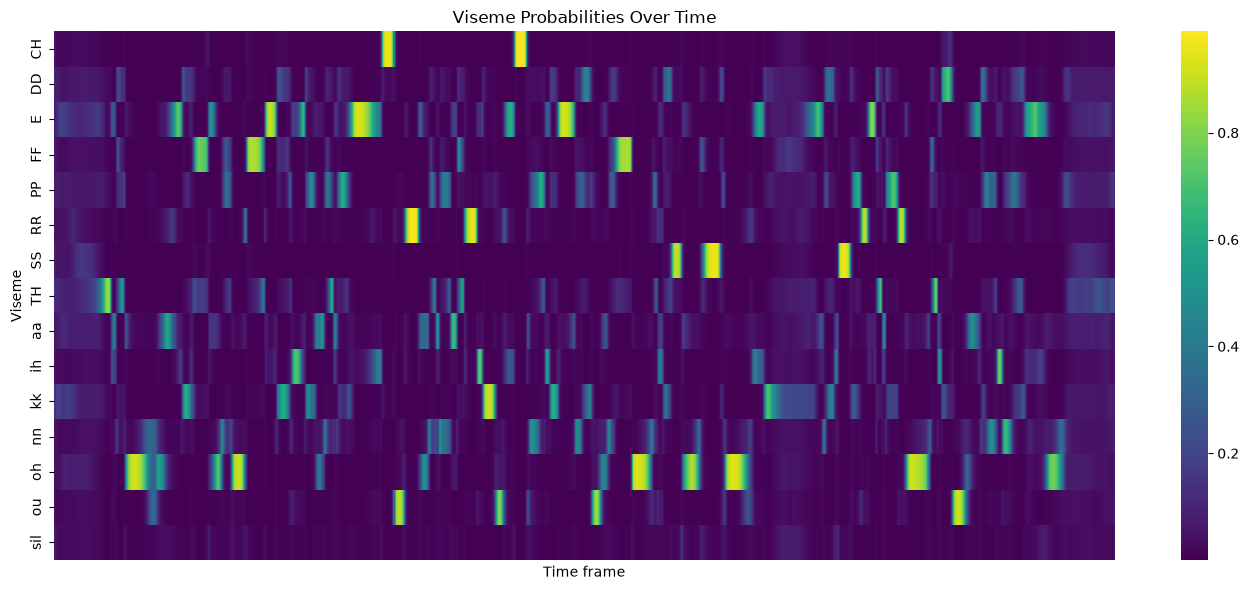

In [7]:
plt.figure(figsize=(14, 6))

sns.heatmap(
    probs.T,
    cmap="viridis",
    yticklabels=labels,
    xticklabels=False,
)

plt.title("Viseme Probabilities Over Time")
plt.xlabel("Time frame")
plt.ylabel("Viseme")
plt.tight_layout()
plt.show()

In [8]:
pred_ids = probs.argmax(axis=1)
pred_labels = [labels[i] for i in pred_ids]

def collapse_repeated(sequence):
    collapsed = []

    for item in sequence:
        if len(collapsed) == 0 or collapsed[-1] != item:
            collapsed.append(item)

    return collapsed

collapsed_visemes = collapse_repeated(pred_labels)

print("Collapsed predicted visemes:")
print(" ".join(collapsed_visemes[:100]))

Collapsed predicted visemes:
kk E kk E SS TH aa nn FF TH oh ou oh aa E kk FF E oh nn PP oh RR FF TH E kk PP ih E kk PP kk aa oh aa nn PP TH aa PP kk E ih CH ou RR E aa oh nn PP TH aa nn PP nn aa FF TH RR ih kk ou E CH aa nn PP ih kk E nn PP DD kk ou oh nn PP FF oh nn PP TH ih kk DD SS oh nn FF SS DD PP oh ou ih E kk
